# 합성곱 신경망을 사용한 이미지 분류

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image

from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets
from torchinfo import summary
from torchviz import make_dot

In [2]:
# 재현성
torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

In [3]:
# GPU(집 PC) / CPU(노트북) 자동 선택
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

device: cpu


In [4]:
# 데이터 로드 (keras.datasets.fashion_mnist 대체)
train_set = datasets.FashionMNIST(root='./data', train=True, download=True)
test_set = datasets.FashionMNIST(root='./data', train=False, download=True)

train_input, train_target = train_set.data.numpy(), train_set.targets.numpy()
test_input, test_target = test_set.data.numpy(), test_set.targets.numpy()
print(train_input.shape, train_target.shape)

train_scaled, test_scaled = train_input / 255.0, test_input / 255.0
train_scaled, val_scaled, train_target, val_target = train_test_split(
    train_scaled, train_target, test_size=0.2, random_state=42
)
print(train_scaled.shape, train_target.shape)
print(val_scaled.shape, val_target.shape)
print(test_scaled.shape, test_target.shape)

(60000, 28, 28) (60000,)
(48000, 28, 28) (48000,)
(12000, 28, 28) (12000,)
(10000, 28, 28) (10000,)


In [5]:
# numpy -> tensor, PyTorch는 channels-first: (N, 1, 28, 28)
def to_tensor(x, y):
    x = torch.tensor(x, dtype=torch.float32).unsqueeze(1)
    y = torch.tensor(y, dtype=torch.long)
    return x, y

train_x, train_y = to_tensor(train_scaled, train_target)
val_x, val_y = to_tensor(val_scaled, val_target)
test_x, test_y = to_tensor(test_scaled, test_target)

In [6]:
train_loader = DataLoader(TensorDataset(train_x, train_y), batch_size=32, shuffle=True)
val_loader = DataLoader(TensorDataset(val_x, val_y), batch_size=256)
test_loader = DataLoader(TensorDataset(test_x, test_y), batch_size=256)

In [11]:
# 모델 (마지막 softmax는 CrossEntropyLoss에 포함되므로 제거)
model = nn.Sequential(
    nn.Conv2d(1, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(64 * 7 * 7, 100),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(100, 10),
).to(device)

# model.summary() 대체
summary(model, input_size=(1, 1, 28, 28))

# model.layers 대체
list(model.children())

[Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)),
 ReLU(),
 MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False),
 Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)),
 ReLU(),
 MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False),
 Flatten(start_dim=1, end_dim=-1),
 Linear(in_features=3136, out_features=100, bias=True),
 ReLU(),
 Dropout(p=0.4, inplace=False),
 Linear(in_features=100, out_features=10, bias=True)]

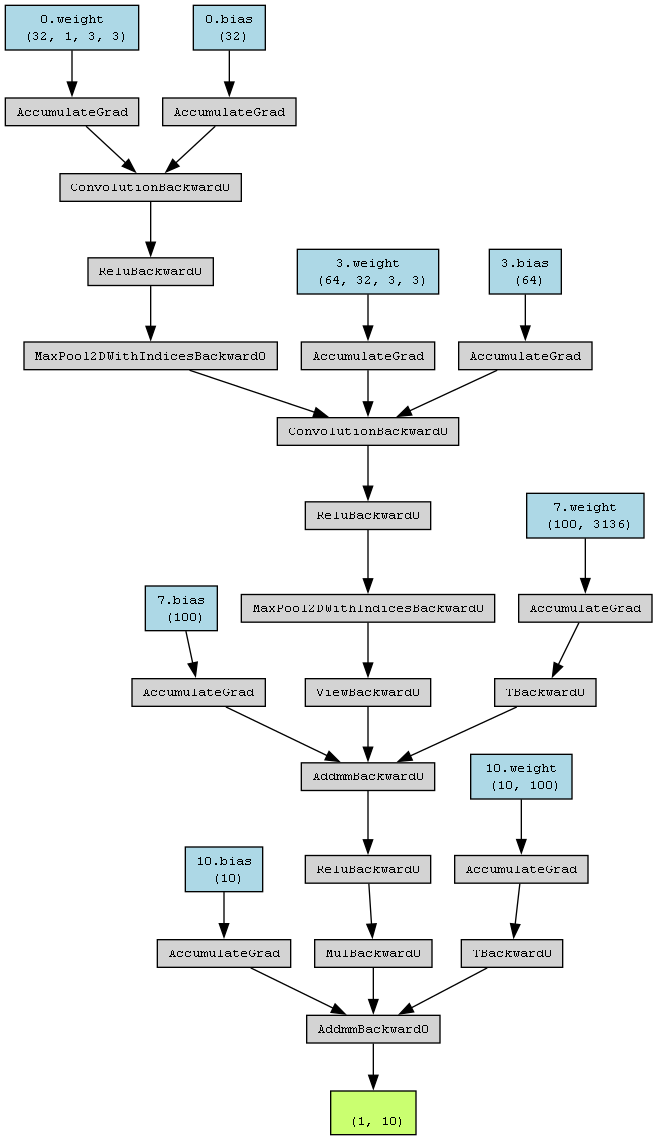

In [ ]:
# plot_model 대체: 구조 시각화가 필요하면 torchviz 사용 (pip install torchviz, graphviz 필요)
make_dot(model(torch.zeros(1, 1, 28, 28, device=device)), params=dict(model.named_parameters())).render('model', format='png')
Image("./model.png")

In [14]:
# compile 대체
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters())

In [15]:
def evaluate(loader):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += criterion(out, y).item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n

In [16]:
# fit + ModelCheckpoint + EarlyStopping(patience=2, restore_best_weights=True)
best_cnn_model_path = './best-cnn-model.pt'
epochs, patience = 20, 2
best_val_loss, wait, stopped_epoch = float('inf'), 0, 0
history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}

for epoch in range(epochs):
    model.train()
    run_loss, correct, n = 0.0, 0, 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        run_loss += loss.item() * len(y)
        correct += (out.argmax(1) == y).sum().item()
        n += len(y)

    train_loss, train_acc = run_loss / n, correct / n
    val_loss, val_acc = evaluate(val_loader)
    history['loss'].append(train_loss)
    history['accuracy'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_accuracy'].append(val_acc)
    print(f'Epoch {epoch+1}/{epochs} - loss: {train_loss:.4f} - acc: {train_acc:.4f} '
          f'- val_loss: {val_loss:.4f} - val_acc: {val_acc:.4f}')

    if val_loss < best_val_loss:          # checkpoint (save_best_only)
        best_val_loss = val_loss
        torch.save(model.state_dict(), best_cnn_model_path)
        wait = 0
    else:                                 # early stopping
        wait += 1
        if wait >= patience:
            stopped_epoch = epoch
            break

model.load_state_dict(torch.load(best_cnn_model_path, map_location=device))  # restore_best_weights
print(stopped_epoch)

Epoch 1/20 - loss: 0.5696 - acc: 0.7930 - val_loss: 0.3498 - val_acc: 0.8728
Epoch 2/20 - loss: 0.3784 - acc: 0.8655 - val_loss: 0.2838 - val_acc: 0.8961
Epoch 3/20 - loss: 0.3267 - acc: 0.8832 - val_loss: 0.2784 - val_acc: 0.8957
Epoch 4/20 - loss: 0.2948 - acc: 0.8940 - val_loss: 0.2579 - val_acc: 0.9053
Epoch 5/20 - loss: 0.2698 - acc: 0.9011 - val_loss: 0.2466 - val_acc: 0.9076
Epoch 6/20 - loss: 0.2510 - acc: 0.9080 - val_loss: 0.2453 - val_acc: 0.9084
Epoch 7/20 - loss: 0.2325 - acc: 0.9154 - val_loss: 0.2266 - val_acc: 0.9162
Epoch 8/20 - loss: 0.2182 - acc: 0.9194 - val_loss: 0.2277 - val_acc: 0.9197
Epoch 9/20 - loss: 0.2043 - acc: 0.9241 - val_loss: 0.2234 - val_acc: 0.9228
Epoch 10/20 - loss: 0.1912 - acc: 0.9288 - val_loss: 0.2370 - val_acc: 0.9198
Epoch 11/20 - loss: 0.1783 - acc: 0.9325 - val_loss: 0.2304 - val_acc: 0.9196
10


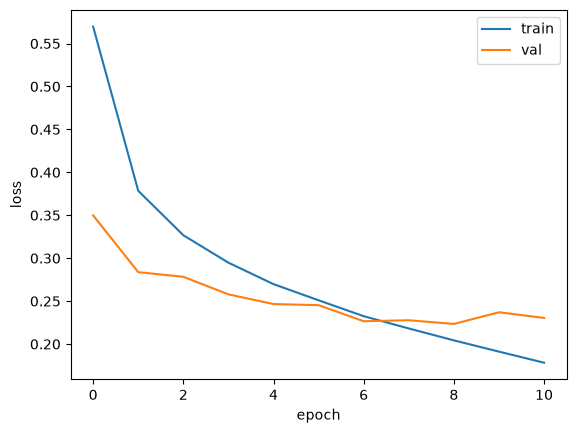

In [17]:
plt.plot(history['loss'])
plt.plot(history['val_loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend(['train', 'val'])
plt.show()

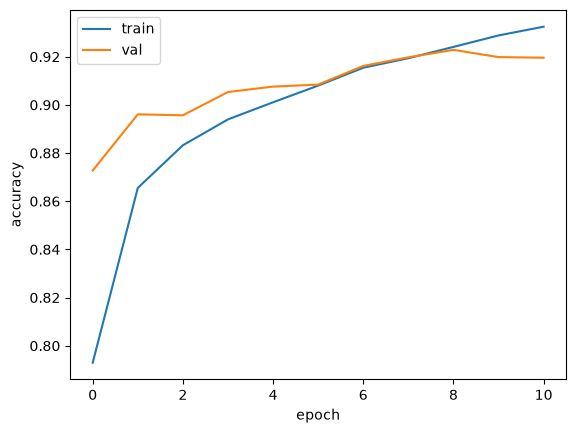

In [18]:
plt.plot(history['accuracy'])
plt.plot(history['val_accuracy'])
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.legend(['train', 'val'])
plt.show()

In [19]:
print(evaluate(val_loader))  # (loss, accuracy)

(0.2234473108847936, 0.9228333333333333)


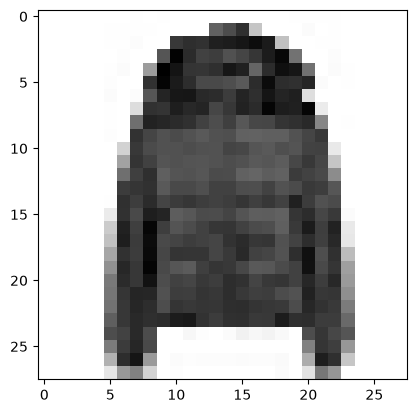

In [24]:
sample = 3
plt.imshow(val_scaled[sample].reshape(28, 28), cmap='gray_r')
plt.show()

In [25]:
classes = ['티셔츠', '바지', '스웨터', '드레스', '코트', '샌달', '셔츠', '스니커즈', '가방', '앵클 부츠']
model.eval()
with torch.no_grad():
    logits = model(val_x[sample:sample+1].to(device))
    pred = torch.softmax(logits, dim=1).cpu().numpy()
print(pred)
print(np.argmax(pred), classes[np.argmax(pred)])

[[1.8691420e-05 3.3542724e-10 1.3483826e-02 1.1788593e-06 9.5277226e-01
  1.6819447e-09 3.3722725e-02 1.2926181e-09 1.3366702e-06 1.2675779e-09]]
4 코트


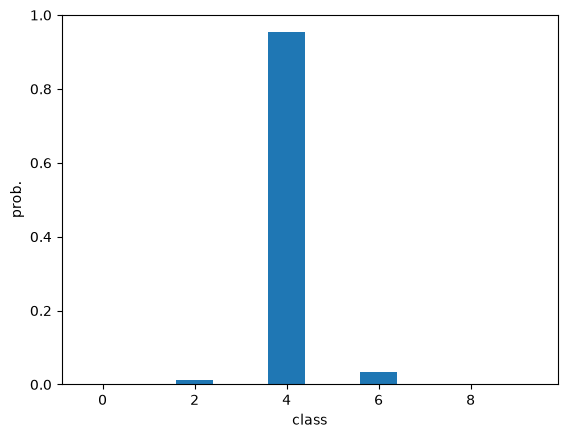

In [27]:
plt.bar(range(10), pred[0])
plt.xlabel('class')
plt.ylabel('prob.')
plt.show()

In [28]:
print(test_scaled.shape, test_target.shape)
print(evaluate(test_loader))  # (loss, accuracy)

(10000, 28, 28) (10000,)
(0.2514234783887863, 0.9149)
